# 04 - Scenario analysis

Comparison of S1-S7 (all evaluated with the same AC time-series power flow) and the uncontrolled PV x EV sweep.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.config import load_config
from src.analysis import visualization as viz
viz.apply_style()
config = load_config(ROOT / "config" / "config.yaml")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
pd.read_csv(ROOT / 'results' / 'scenario_comparison.csv').set_index('Scenario').T

Scenario,S1 Baseline,S2 High PV,S3 High EV (uncontr.),S4 PV + EV,S5 PV + EV + BESS (rule),S6 Smart charging,S7 Smart charging + BESS
Peak grid import [kW],3087.0000,2786.0000,3989.0000,3516.0000,3127.0000,2786.0000,2380.0000
Min voltage [pu],0.9329,0.9283,0.9115,0.9238,0.9299,0.9283,0.9508
Max voltage [pu],1.0145,1.0129,1.0137,1.0137,1.0185,1.0112,1.0107
Voltage violation [h],14.0000,3.5000,15.5000,4.7500,3.7500,3.5000,0.0000
Violation bus-steps [-],540.0000,130.0000,712.0000,142.0000,90.0000,130.0000,0.0000
Max line loading [%],41.7000,36.5000,49.4000,43.6000,40.0000,36.5000,32.5000
Max trafo loading [%],76.1000,65.8000,90.1000,79.5000,73.1000,65.8000,58.5000
Grid losses [kWh],2284.0000,1248.0000,2576.0000,1443.0000,1407.0000,1400.0000,1419.0000
Grid import [kWh],57473.0000,23231.0000,62066.0000,27619.0000,27635.0000,27576.0000,26915.0000
Grid export [kWh],0.0000,4930.0000,0.0000,4822.0000,4409.0000,4822.0000,3977.0000


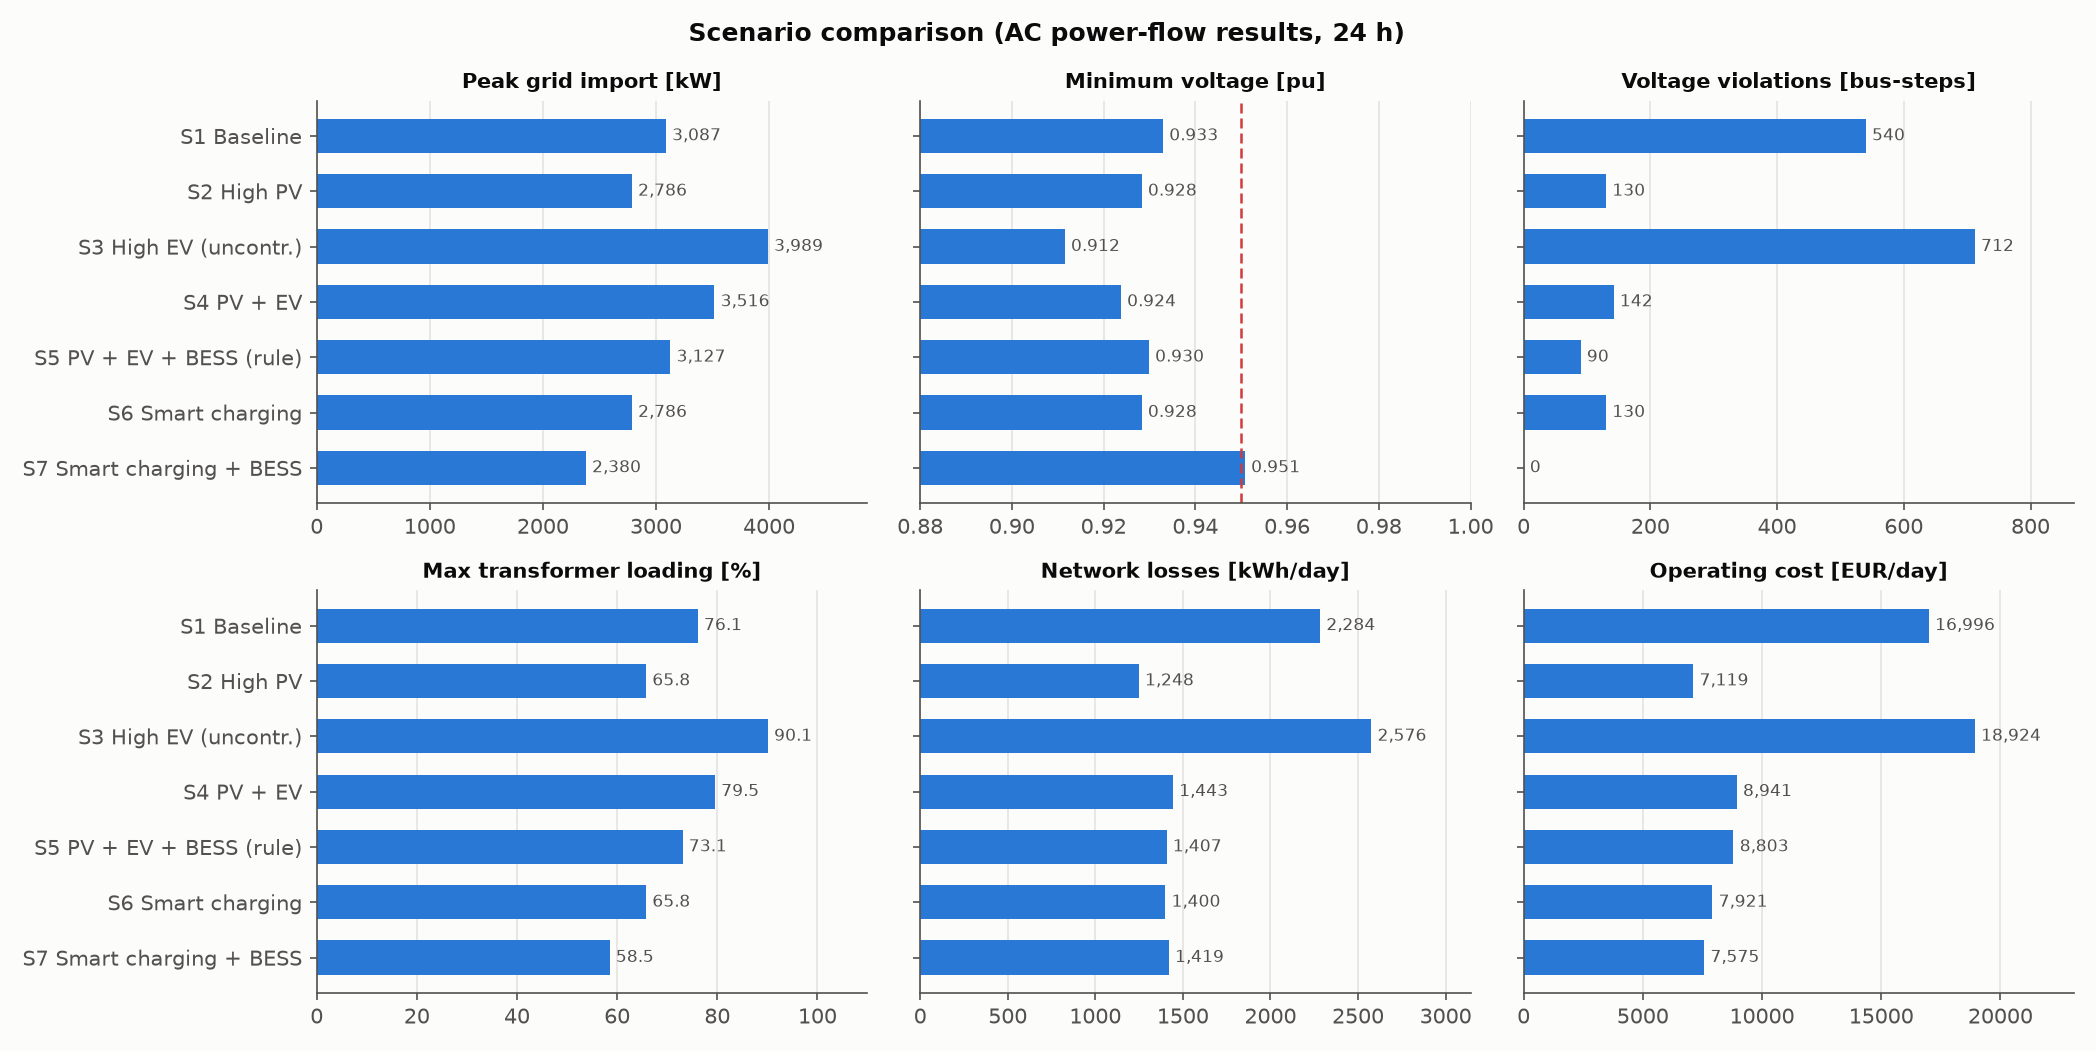

In [3]:
from IPython.display import Image
Image(filename=str(ROOT / 'results' / 'figures' / '10_scenario_comparison.png'))

### PV x EV sweep (uncontrolled, no BESS)

In [4]:
sweep = pd.read_csv(ROOT / 'results' / 'tables' / 'experiment_pv_ev.csv')
sweep.pivot(index='ev_level', columns='pv_penetration_pct', values='voltage_violation_bus_steps')

pv_penetration_pct,0,25,50,75,100
ev_level,,,,,
high,712,393,243,181,166
low,622,277,119,82,72
medium,681,357,191,126,111


In [5]:
sweep.pivot(index='ev_level', columns='pv_penetration_pct', values='peak_import_kw').round(0)

pv_penetration_pct,0,25,50,75,100
ev_level,,,,,
high,3989.0,3809.0,3660.0,3573.0,3535.0
low,3359.0,3189.0,3099.0,3058.0,3048.0
medium,3576.0,3428.0,3312.0,3283.0,3274.0


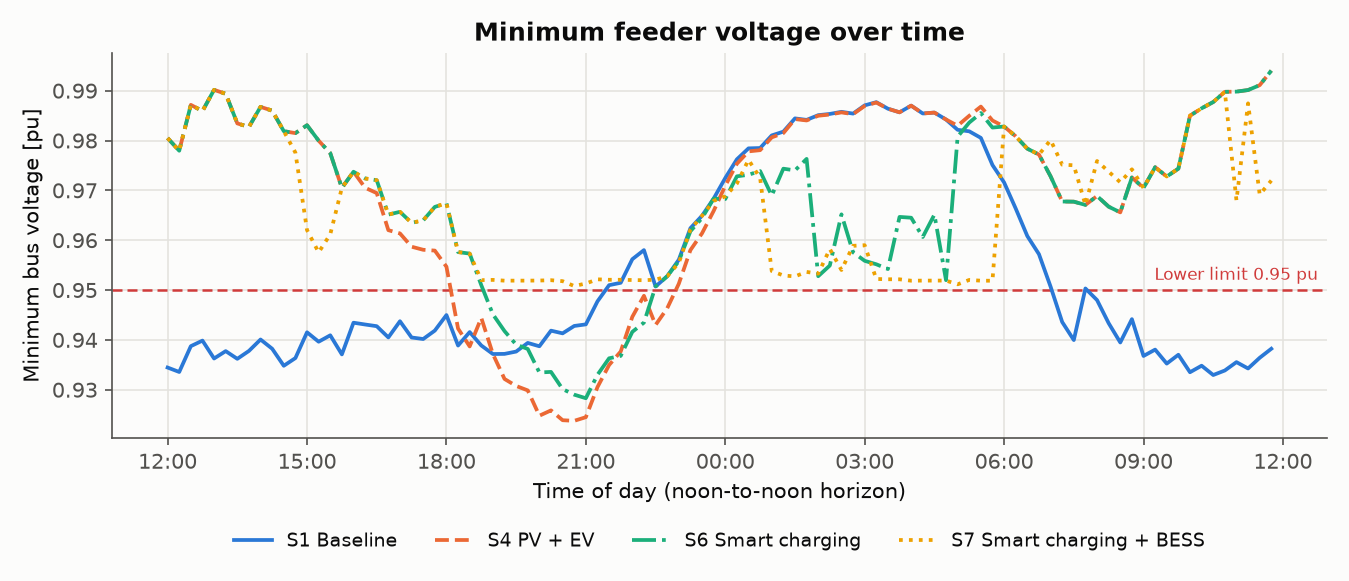

In [6]:
Image(filename=str(ROOT / 'results' / 'figures' / '07_min_voltage.png'))